# Phase 2: Cleaning
What phase 1 showed:
- train has lots of NaNs and a suspicious value 9999.0 on every channel, test looks clean
- 44 duplicate rows in train
- some cells hold the text "unknown" 

What's the Plan for this phase: find out how the bad values are spread, drop duplicates, replace bad values
by interpolating inside each window. Interpolation only uses the same window and
channel, so nothing is learned from other rows and there is no leakage between
train and validation.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "."
train = pd.read_csv(f"{DATA_DIR}/train.csv", low_memory=False)
test = pd.read_csv(f"{DATA_DIR}/test.csv", low_memory=False)

signal_cols = [c for c in train.columns if c not in ("id", "target")]
n_steps, n_channels = 250, 23

channels = [c.split("_", 1)[1] for c in signal_cols[:n_channels]]

## 0. Text entries inside the signal columns
Loading gave a DtypeWarning and the reshape crashed on the string "unknown", so some
cells are text. My phase 1 check looked for dtype "object", but newer pandas stores
text as its own "str" dtype, so it missed them. Look at the values directly instead.

In [ ]:
def non_numeric_tokens(df):
    raw = df[signal_cols]
    as_num = raw.apply(pd.to_numeric, errors="coerce")
    is_text = as_num.isna() & raw.notna()      
    tokens = pd.Series(raw.where(is_text).to_numpy().ravel()).dropna()
    return tokens, int(raw.isna().to_numpy().sum())

for name, df in [("train", train), ("test", test)]:
    tokens, empty = non_numeric_tokens(df)
    print(name, "- text entries:", len(tokens), " truly empty cells:", empty)
    print(tokens.value_counts().head(10))
    print()

train - text entries: 87000  truly empty cells: 429835
-          11949
unknown    11933
?          11827
9999,00     2550
0,36         363
0,37         314
0,55         300
0,18         273
-0,72        271
0,01         262
Name: count, dtype: int64

test - text entries: 0  truly empty cells: 0
Series([], Name: count, dtype: int64)



## 1. Duplicates

In [7]:
dup_id = train["id"].duplicated(keep=False)
dup_full = train.duplicated(keep=False)
print("rows whose id appears more than once:", dup_id.sum())
print("rows that are exact copies (id + signals + label):", dup_full.sum())

#do copies of the same id ever have different labels?
labels_per_id = train[dup_id].groupby("id")["target"].nunique()
print("ids with conflicting labels:", (labels_per_id > 1).sum())

#keep the first copy of every row
train_u = train.drop_duplicates().reset_index(drop=True)
print("\nbefore:", train.shape, " after:", train_u.shape)
print("ids unique now:", train_u["id"].is_unique)

rows whose id appears more than once: 88
rows that are exact copies (id + signals + label): 88
ids with conflicting labels: 0

before: (679, 5752)  after: (635, 5752)
ids unique now: True


In [ ]:
def to_3d(df):
    nums = df[signal_cols].apply(pd.to_numeric, errors="coerce")
    return nums.to_numpy(dtype=np.float64).reshape(-1, n_steps, n_channels)

X_train = to_3d(train_u)
X_test = to_3d(test)
y_train = train_u["target"].to_numpy()
ids_train = train_u["id"].to_numpy()
print(X_train.shape, X_test.shape)

(635, 250, 23) (403, 250, 23)


## 2. What are the huge values?

We looked at every reading above 1000, There was only one distinct value: exactly 9999 gotta remove this

In [ ]:
big = X_train[X_train > 1000]
vals, cnt = np.unique(big, return_counts=True)
print("distinct values above 1000 in train:", vals[:10], cnt[:10])
print("readings above 1000 in train:", big.size, "->", round(big.size / X_train.size, 4), "of all readings")
print("NaN share in train:", round(np.isnan(X_train).mean(), 4))


print("\nreadings above 1000 in test:", int((X_test > 1000).sum()))
print("NaNs in test:", int(np.isnan(X_test).sum()))

distinct values above 1000 in train: [9999.] [159788]
readings above 1000 in train: 159788 -> 0.0438 of all readings
NaN share in train: 0.1323

readings above 1000 in test: 0
NaNs in test: 0


## 3. Where are the bad values?
A reading is bad if it is NaN or exactly 9999

In [10]:
SENTINEL = 9999.0

def bad_mask(X):
    return np.isnan(X) | np.isclose(X, SENTINEL)

bad_tr = bad_mask(X_train)
bad_te = bad_mask(X_test)
print("bad share  train:", round(bad_tr.mean(), 4), " test:", round(bad_te.mean(), 4))

print("\nbad share per channel (train):")
print(pd.Series(bad_tr.mean(axis=(0, 1)), index=channels).round(3))

bad share  train: 0.1761  test: 0.0

bad share per channel (train):
chest_acc_x     0.176
chest_acc_y     0.176
chest_acc_z     0.176
chest_ecg_1     0.176
chest_ecg_2     0.177
ankle_acc_x     0.175
ankle_acc_y     0.176
ankle_acc_z     0.176
ankle_gyro_x    0.176
ankle_gyro_y    0.177
ankle_gyro_z    0.176
ankle_mag_x     0.176
ankle_mag_y     0.176
ankle_mag_z     0.176
arm_acc_x       0.176
arm_acc_y       0.176
arm_acc_z       0.176
arm_gyro_x      0.176
arm_gyro_y      0.176
arm_gyro_z      0.176
arm_mag_x       0.176
arm_mag_y       0.176
arm_mag_z       0.176
dtype: float64


In [ ]:

per_step = bad_tr.sum(axis=2)
print("steps with at least one bad channel:", round((per_step > 0).mean(), 3))
print("steps where all 23 channels are bad:", round((per_step == n_channels).mean(), 4))
print("average share of bad channels per step:", round(per_step.mean() / n_channels, 3))

win_bad = bad_tr.mean(axis=(1, 2))
print("\nshare of bad readings per window:")
print(pd.Series(win_bad).describe().round(3))
print("windows with more than 50% bad:", int((win_bad > 0.5).sum()))

print("\nmean bad share per class:")
print(pd.Series(win_bad).groupby(y_train).mean().round(3).sort_values())

steps with at least one bad channel: 0.988
steps where all 23 channels are bad: 0.0
average share of bad channels per step: 0.176

share of bad readings per window:
count    635.000
mean       0.176
std        0.005
min        0.162
25%        0.173
50%        0.176
75%        0.179
max        0.192
dtype: float64
windows with more than 50% bad: 0

mean bad share per class:
arm_elevation      0.175
jogging            0.175
climbing_stairs    0.176
cycling            0.176
running            0.176
lying              0.176
waist_bends        0.176
sitting            0.176
walking            0.176
knees_bending      0.177
jump_front_back    0.177
standing           0.177
dtype: float64


In [ ]:

def longest_run(b):
    best = cur = 0
    for v in b:
        cur = cur + 1 if v else 0
        best = max(best, cur)
    return best

runs = np.array([[longest_run(bad_tr[i, :, c]) for c in range(n_channels)]
                 for i in range(bad_tr.shape[0])])
print(pd.Series(runs.ravel()).describe().round(1))
print("series that are completely bad:", int((runs == n_steps).sum()))

count    14605.0
mean         2.9
std          0.8
min          1.0
25%          2.0
50%          3.0
75%          3.0
max          8.0
dtype: float64
series that are completely bad: 0


## 4. Cleaning
For each window and channel, mark bad readings and fill them by linear interpolation
between the nearest good readings. At the edges `np.interp` just repeats the nearest
good value. If a whole series is bad there is nothing to interpolate from, those are
left as NaN and counted.

In [13]:
def fill_bad(X):
    X = X.copy()
    bad = bad_mask(X)
    t = np.arange(X.shape[1])
    n_empty = 0
    for i in range(X.shape[0]):
        for c in range(X.shape[2]):
            b = bad[i, :, c]
            if not b.any():
                continue
            good = ~b
            if good.sum() == 0:
                n_empty += 1
                X[i, :, c] = np.nan
                continue
            X[i, b, c] = np.interp(t[b], t[good], X[i, good, c])
    return X, n_empty

X_train_c, empty_tr = fill_bad(X_train)
X_test_c, empty_te = fill_bad(X_test)
print("fully bad series  train:", empty_tr, " test:", empty_te)
print("NaNs left         train:", int(np.isnan(X_train_c).sum()), " test:", int(np.isnan(X_test_c).sum()))
print("values above 1000 train:", int((X_train_c > 1000).sum()), " test:", int((X_test_c > 1000).sum()))

fully bad series  train: 0  test: 0
NaNs left         train: 0  test: 0
values above 1000 train: 0  test: 0


## 5. Before and after
Top row is the raw window (NaN gaps show up as breaks), bottom row is the cleaned one.

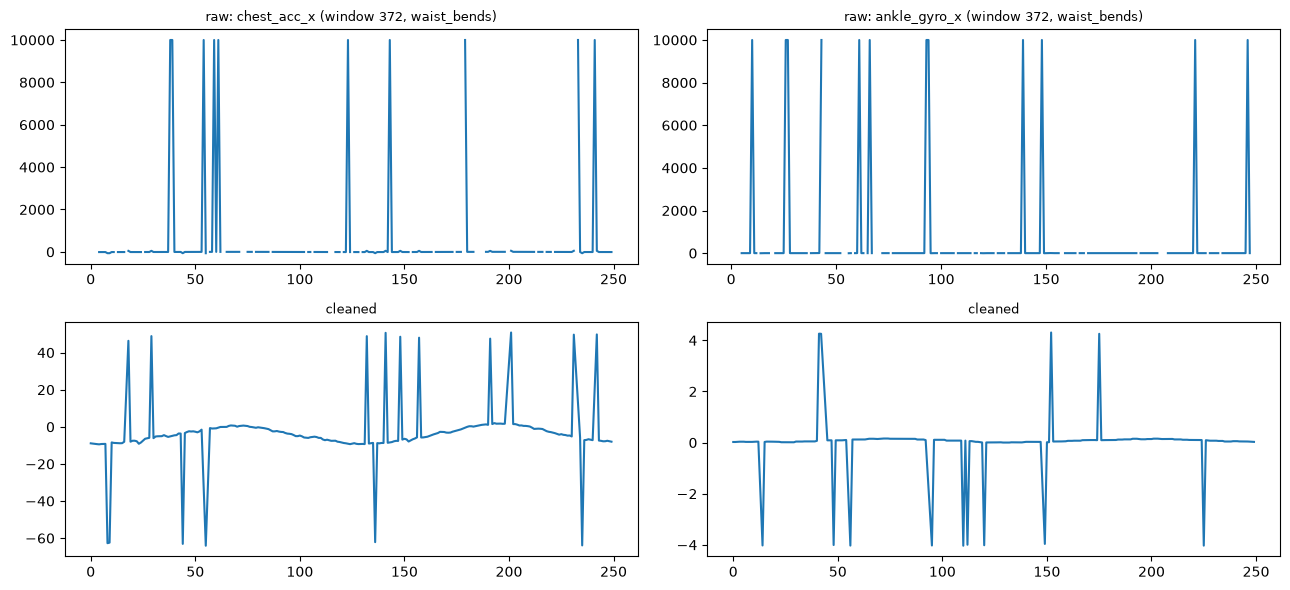

In [14]:
i = int(np.argmax(win_bad))   # the window with the most bad readings
fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for col, ch in enumerate([0, 8]):
    axes[0, col].plot(X_train[i, :, ch])
    axes[0, col].set_title(f"raw: {channels[ch]} (window {i}, {y_train[i]})", fontsize=9)
    axes[1, col].plot(X_train_c[i, :, ch])
    axes[1, col].set_title("cleaned", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Stats again after cleaning
The train vs test shift from phase 1 was fake (caused by the 9999s), so redo it.

In [15]:
tr = X_train_c.reshape(-1, n_channels)
te = X_test_c.reshape(-1, n_channels)
tr_std = tr.std(axis=0)
safe = np.where(tr_std == 0, 1, tr_std)

summary = pd.DataFrame({
    "train_mean": tr.mean(axis=0),
    "train_std": tr_std,
    "test_mean": te.mean(axis=0),
    "test_std": te.std(axis=0),
    "mean_shift": (te.mean(axis=0) - tr.mean(axis=0)) / safe,
    "std_ratio": te.std(axis=0) / safe,
}, index=channels)
pd.set_option("display.width", 200)
print(summary.round(3))

              train_mean  train_std  test_mean  test_std  mean_shift  std_ratio
chest_acc_x       -7.489     13.280     -7.589     5.676      -0.008      0.427
chest_acc_y       -0.155      7.036      0.024     1.921       0.025      0.273
chest_acc_z       -1.014     10.575     -0.545     4.976       0.044      0.471
chest_ecg_1       -0.007      2.070     -0.025     0.686      -0.009      0.331
chest_ecg_2       -0.019      1.943     -0.015     0.724       0.002      0.372
ankle_acc_x        2.016      9.875      1.584     4.277      -0.044      0.433
ankle_acc_y       -9.121     11.988     -8.964     5.283       0.013      0.441
ankle_acc_z       -0.371     14.915     -1.249     6.469      -0.059      0.434
ankle_gyro_x       0.155      0.981      0.077     0.484      -0.079      0.493
ankle_gyro_y      -0.518      1.041     -0.612     0.390      -0.089      0.374
ankle_gyro_z      -0.131      1.371     -0.106     0.523       0.019      0.381
ankle_mag_x        0.838    181.240     

In [ ]:

print("constant channels:", [c for c, s in zip(channels, tr_std) if s == 0])

z_tr = np.abs((tr - tr.mean(axis=0)) / safe)
z_te = np.abs((te - tr.mean(axis=0)) / safe)    # test measured with train mean/std
outliers = pd.DataFrame({
    "train |z|>5": (z_tr > 5).mean(axis=0),
    "test |z|>5": (z_te > 5).mean(axis=0),
}, index=channels)
print(outliers.round(4))

constant channels: []
              train |z|>5  test |z|>5
chest_acc_x        0.0000      0.0000
chest_acc_y        0.0000      0.0000
chest_acc_z        0.0000      0.0000
chest_ecg_1        0.0003      0.0000
chest_ecg_2        0.0026      0.0000
ankle_acc_x        0.0002      0.0000
ankle_acc_y        0.0000      0.0000
ankle_acc_z        0.0000      0.0000
ankle_gyro_x       0.0000      0.0000
ankle_gyro_y       0.0000      0.0000
ankle_gyro_z       0.0000      0.0000
ankle_mag_x        0.0000      0.0000
ankle_mag_y        0.0014      0.0000
ankle_mag_z        0.0045      0.0028
arm_acc_x          0.0000      0.0000
arm_acc_y          0.0000      0.0000
arm_acc_z          0.0000      0.0000
arm_gyro_x         0.0000      0.0000
arm_gyro_y         0.0000      0.0000
arm_gyro_z         0.0000      0.0000
arm_mag_x          0.0000      0.0000
arm_mag_y          0.0019      0.0001
arm_mag_z          0.0007      0.0000


## 7. Class counts after dropping duplicates

In [17]:
counts = pd.Series(y_train).value_counts()
print(counts)
print("\nmajority baseline:", round(counts.max() / counts.sum(), 3))

lying              60
cycling            59
jogging            59
walking            59
standing           58
sitting            58
running            58
climbing_stairs    54
arm_elevation      54
knees_bending      50
waist_bends        49
jump_front_back    17
Name: count, dtype: int64

majority baseline: 0.094


## 8. Save the cleaned data
Next notebooks load this file instead of cleaning again.

In [18]:
np.savez_compressed(
    "clean_data.npz",
    X_train=X_train_c,
    y_train=y_train.astype(str),
    train_ids=ids_train.astype(str),
    X_test=X_test_c,
    test_ids=test["id"].to_numpy().astype(str),
    channels=np.array(channels),
)
print("saved clean_data.npz")

saved clean_data.npz
